[[0.         0.         0.         0.         0.         0.        ]
 [0.33333333 0.         0.         0.         0.         0.90609394]
 [0.66666667 0.         0.         0.         0.         1.81218789]
 [1.         0.         0.         0.         0.         2.71828183]
 [1.33333333 0.         0.         0.         0.         3.62437577]
 [1.66666667 0.         0.         0.         0.         4.53046971]
 [2.         2.44280552 2.9836494  3.6442376  4.45108186 5.43656366]]
[[0.         0.         0.         0.         0.         0.        ]
 [0.33333333 0.40726462 0.49748325 0.60759608 0.74200707 0.90609394]
 [0.66666667 0.81452375 0.99495758 1.21518318 1.48400854 1.81218789]
 [1.         1.22176621 1.49240473 1.82274271 2.2259927  2.71828183]
 [1.33333333 1.62896369 1.9897783  2.43022656 2.96792825 3.62437577]
 [1.66666667 2.03604232 2.48695839 3.0375055  3.70972407 4.53046971]
 [2.         2.44280552 2.9836494  3.6442376  4.45108186 5.43656366]]


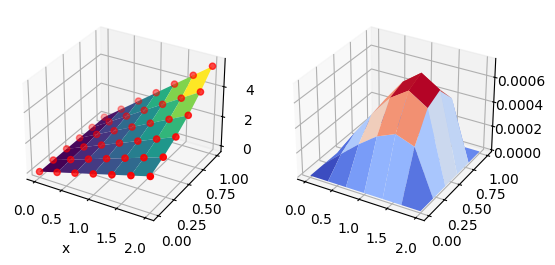

62
0.000734827458387155


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# input
a = 0.0
b = 2.0
c = 0.0
d = 1.0
n = 6
m = 5
h = (b-a)/n
k = (d-c)/m
TOL = 1e-10
N = 100

x = np.linspace(a,b,n+1)
y = np.linspace(c,d,m+1)
xx,yy = np.meshgrid(x,y,indexing='ij')

w = np.zeros((n+1,m+1))
# Dirichlet B.C.
w[:,0] = x
w[0,:] = 0.0
w[:,-1] = np.exp(1)*x
w[-1,:] = 2*np.exp(y)

print(w)

err = 1.0;
it = 0
while it < N and err > TOL:
  err = 0.0;
  for i in range(1,n):
    for j in range(1,m):
        w_new = (w[i+1,j]+w[i-1,j]
                 +((h/k)**2)*(w[i,j+1]+w[i,j-1])
                 -h**2*x[i]*np.exp(y[j]))/(2*(1+(h/k)**2))
        err = max(err, abs(w_new-w[i,j]))
        w[i,j] = w_new
  it += 1 # it = it + 1

print(w)

exactS = xx*np.exp(yy)

fig = plt.figure()
ax = fig.add_subplot(1,2,1,projection='3d')
surf = ax.plot_surface(xx,yy,w,cmap='viridis')
ax.scatter(xx,yy,exactS,color='r')
ax.set_xlabel('x')

ax2 = fig.add_subplot(1,2,2,projection='3d')
ax2.plot_surface(xx,yy,w-exactS,cmap='coolwarm')
plt.show()

print(it)
print(np.abs(w-exactS).max())

In [ ]:
print

[[0.    0.    0.    0.    0.   ]
 [0.125 0.125 0.125 0.125 0.125]
 [0.25  0.25  0.25  0.25  0.25 ]
 [0.375 0.375 0.375 0.375 0.375]
 [0.5   0.5   0.5   0.5   0.5  ]]


In [ ]:
print(yy)

[[0.    0.125 0.25  0.375 0.5  ]
 [0.    0.125 0.25  0.375 0.5  ]
 [0.    0.125 0.25  0.375 0.5  ]
 [0.    0.125 0.25  0.375 0.5  ]
 [0.    0.125 0.25  0.375 0.5  ]]


In [ ]:
print(w)

[[  0.           0.           0.           0.           0.        ]
 [  0.           6.24999949  12.49999949  18.74999974  25.        ]
 [  0.          12.49999949  24.99999949  37.49999974  50.        ]
 [  0.          18.74999974  37.49999974  56.24999987  75.        ]
 [  0.          25.          50.          75.         100.        ]]
